# 05 · Classical machine learning

Every model forecasts the next trading day for each pair through the same monthly walk-forward folds as the baselines (`scripts/run_ml.py`).

- **Features:** the 46 Phase 2 features, a GARCH(1,1) variance forecast and the three currency factor returns. The last two are refitted every January on earlier days only.
- **Tuning:** hyperparameters are chosen once a year on the validation slice (the last 20% of the training window, after a 5 day embargo) and reused for that year's monthly refits.
- **Volatility** models predict log realized variance; a scale factor fitted on the validation slice turns that into a variance forecast.
- **Regime-aware variants** of ridge, logistic regression and LightGBM either add the probability of the turbulent regime as a feature (`_regime`) or train one expert per regime and weight their forecasts by the regime probabilities (`_experts`). Regimes are the walk-forward Gaussian mixture regimes of Phase 3.

Diebold–Mariano tests compare each model with the strongest simple benchmark: HAR-RV for volatility, the zero forecast for returns and the historical frequency of up days for direction. Baselines appear with a `baseline_` prefix. The neural networks of Phase 5 (`mlp`, `lstm`) share these tables and charts; notebook 06 discusses them.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from fxml import viz
from fxml.config import load_config
from fxml.validation.metrics import qlike_losses

cfg = load_config()
viz.apply_style()
tables = cfg.paths.reports / "tables"
vol = pd.read_csv(tables / "ml_volatility.csv")
direction = pd.read_csv(tables / "ml_direction.csv")
ret = pd.read_csv(tables / "ml_returns.csv")
regime_vs_global = pd.read_csv(tables / "ml_regime_vs_global.csv")
hyper = pd.read_csv(tables / "ml_hyperparameters.csv")
curves = pd.read_csv(tables / "ml_learning_curves.csv")
predictions = pd.read_parquet(cfg.paths.reports / "predictions" / "ml.parquet")
state = pd.read_parquet(cfg.paths.processed / "market_state.parquet")
pairs = list(cfg.pairs)
pd.set_option("display.precision", 4)


def group_of(model):
    if model.startswith("baseline_"):
        return "baseline"
    if model in ("mlp", "lstm"):
        return "neural"
    return "regime-aware" if model.endswith(("_regime", "_experts")) else "global"


GROUP_COLORS = {"baseline": viz.INK_MUTED, "global": viz.CATEGORICAL[0],
                "regime-aware": viz.CATEGORICAL[1], "neural": viz.CATEGORICAL[2]}


def model_chart(table, value, reference, xlabel, title, name, lower_is_better=True, bars=True):
    """Average over pairs as a bar (or a tick when values sit far from zero), each pair as a
    dot, models sorted best first."""
    per_pair = table[table.pair != "average"].pivot(index="model", columns="pair", values=value)
    mean = per_pair.mean(axis=1).sort_values(ascending=not lower_is_better)
    per_pair = per_pair.loc[mean.index]
    fig, ax = plt.subplots(figsize=(9, 0.32 * len(mean) + 1.2))
    y = np.arange(len(mean))
    colors = [GROUP_COLORS[group_of(m)] for m in mean.index]
    if bars:
        ax.barh(y, mean, color=colors, height=0.6, alpha=0.35)
    else:
        ax.scatter(mean, y, marker="|", s=260, color=colors, linewidths=2.5, zorder=4)
    for i, model in enumerate(mean.index):
        ax.scatter(per_pair.loc[model], np.full(len(pairs), i), s=12, color=colors[i], zorder=3,
                   edgecolor=viz.SURFACE, linewidth=0.6)
    if reference is not None:
        ax.axvline(reference, color=viz.BASELINE, lw=0.8)
    ax.set_yticks(y, mean.index)
    ax.invert_yaxis()
    ax.grid(axis="x")
    ax.grid(axis="y", visible=False)
    ax.set_xlabel(xlabel)
    ax.set_title(title)
    handles = [plt.Rectangle((0, 0), 1, 1, color=c, alpha=0.5) for c in GROUP_COLORS.values()]
    ax.legend(handles, list(GROUP_COLORS), loc="upper left", bbox_to_anchor=(1.01, 1))
    viz.save(fig, name)
    return mean

## Volatility

QLIKE and log errors: lower is better. `pairs_significantly_better` counts pairs where the model beats HAR-RV (Diebold–Mariano, p < 0.05).

In [2]:
cols = ["qlike", "rmse_log", "mz_r2", "mz_slope", "pairs_significantly_better"]
vol[vol.pair == "average"].set_index("model")[cols].sort_values("qlike")

,qlike,rmse_log,mz_r2,mz_slope,pairs_significantly_better
model,,,,,
lightgbm,0.1470,0.4763,0.5739,0.9923,5.0
lightgbm_hmm,0.1484,0.4764,0.5733,0.9865,5.0
lightgbm_regime,0.1490,0.4775,0.5725,0.9874,5.0
mlp,0.1511,0.4911,0.5660,0.9793,3.0
lightgbm_experts,0.1544,0.4857,0.5606,0.9991,5.0
random_forest,0.1549,0.4861,0.5609,0.9927,3.0
ridge_hmm,0.1553,0.4876,0.5591,0.9812,3.0
lasso,0.1554,0.4881,0.5575,0.9829,3.0
ridge,0.1556,0.4880,0.5590,0.9784,3.0


model
baseline_naive       -37.1658
baseline_ewma        -36.3040
baseline_gjr_garch   -24.9042
baseline_garch       -23.0303
knn                  -15.2436
transformer           -2.4739
lstm                  -0.8650
ridge_experts         -0.6032
baseline_har           0.0000
ridge_regime           1.2942
ridge                  1.3472
ridge_hmm              1.4373
lasso                  1.5236
lightgbm_experts       2.0040
random_forest          2.0749
mlp                    3.7254
lightgbm_regime        5.3974
lightgbm_hmm           5.7426
lightgbm               6.3553
dtype: float64

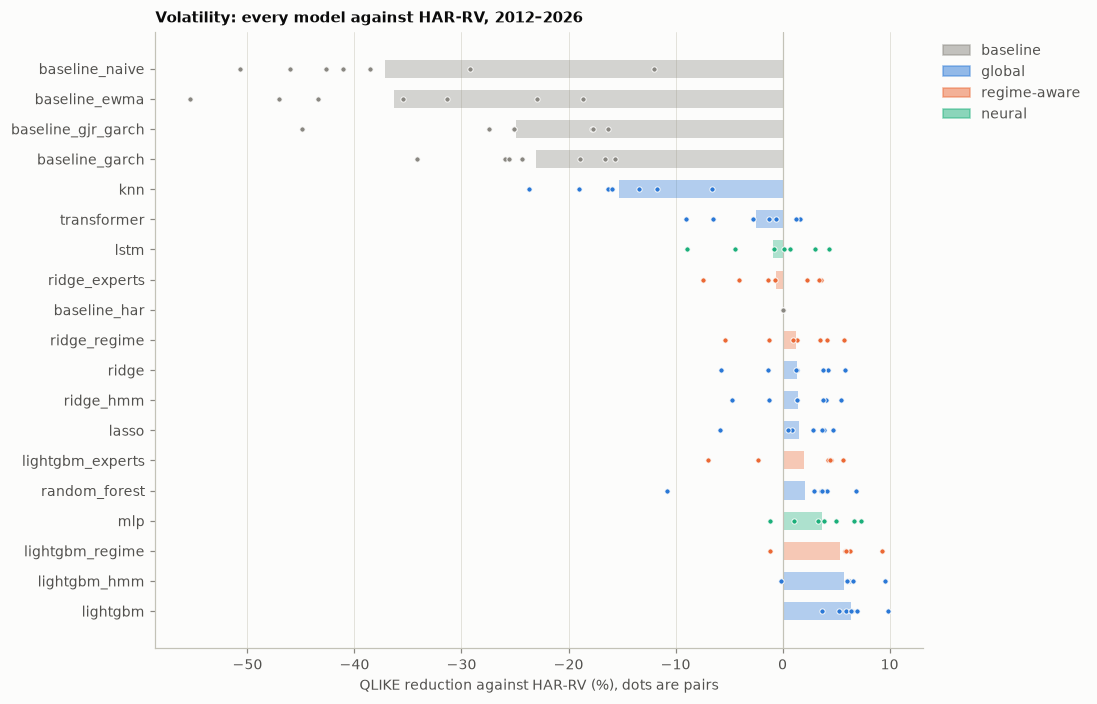

In [3]:
qlike = vol[vol.pair != "average"].pivot(index="pair", columns="model", values="qlike").loc[pairs]
gain = 100 * (1 - qlike.div(qlike["baseline_har"], axis=0))
change = gain.T.reset_index().melt(id_vars="model", var_name="pair", value_name="gain")
model_chart(change, "gain", 0, "QLIKE reduction against HAR-RV (%), dots are pairs",
            "Volatility: every model against HAR-RV, 2012–2026", "ml_volatility_vs_har",
            lower_is_better=False)

In [4]:
vol[vol.pair != "average"].pivot(index="pair", columns="model", values="dm_vs_baseline_har").loc[pairs].round(2)

model,baseline_ewma,baseline_garch,baseline_gjr_garch,baseline_har,baseline_naive,knn,lasso,lightgbm,lightgbm_experts,lightgbm_hmm,lightgbm_regime,lstm,mlp,random_forest,ridge,ridge_experts,ridge_hmm,ridge_regime,transformer
pair,,,,,,,,,,,,,,,,,,,
EURUSD,8.05,5.99,5.27,NaN,12.03,6.96,-1.79,-3.51,-2.79,-3.59,-3.39,-0.24,-1.70,-3.01,-0.79,0.39,-0.79,-0.79,1.11
GBPUSD,4.86,3.49,2.48,NaN,6.84,2.48,-0.24,-1.24,0.34,-1.35,-1.28,0.95,0.25,-1.58,0.29,0.68,0.29,0.27,1.08
USDJPY,5.88,5.55,6.38,NaN,6.44,2.01,-0.26,-2.54,-2.15,-2.79,-2.63,0.31,-0.52,-1.68,-0.72,0.59,-0.78,-0.56,-0.58
USDCHF,1.92,1.77,1.61,NaN,1.10,8.46,3.88,-0.71,2.08,0.08,0.66,1.36,-0.83,1.83,3.76,2.50,3.79,4.06,3.16
AUDUSD,7.87,6.37,6.60,NaN,12.54,5.59,-3.21,-6.12,-2.03,-5.72,-5.92,-1.58,-3.58,-5.86,-3.54,-1.94,-3.23,-3.45,-0.72
USDCAD,8.30,5.70,4.95,NaN,15.12,6.96,-2.78,-3.52,-2.14,-3.19,-3.22,-0.07,-2.17,-1.78,-2.43,-1.31,-2.40,-2.23,0.59
NZDUSD,9.50,6.23,6.41,NaN,13.95,4.37,-2.44,-3.28,-2.29,-3.01,-3.05,-1.12,-4.33,-2.46,-2.44,-1.99,-2.30,-2.38,0.25


## Direction

`pairs_significantly_better` counts pairs where the up/down calls beat chance (Pesaran–Timmermann, p < 0.05).

In [5]:
cols = ["accuracy", "balanced_accuracy", "roc_auc", "brier", "share_called_up", "pairs_significantly_better"]
direction[direction.pair == "average"].set_index("model")[cols].sort_values("roc_auc", ascending=False)

,accuracy,balanced_accuracy,roc_auc,brier,share_called_up,pairs_significantly_better
model,,,,,,
lightgbm_experts,0.5045,0.5039,0.5066,0.2549,0.5304,0.0
lightgbm_hmm,0.5062,0.5054,0.5062,0.2529,0.5408,0.0
logistic_l2_hmm,0.5041,0.5037,0.5056,0.2505,0.6124,0.0
random_forest,0.5042,0.5027,0.5054,0.2507,0.5692,0.0
lightgbm_regime,0.5040,0.5033,0.5048,0.2530,0.5358,0.0
lightgbm,0.5023,0.5016,0.5044,0.2530,0.5364,0.0
naive_bayes,0.5001,0.5024,0.5034,0.2575,0.5425,0.0
mlp,0.5036,0.5031,0.5034,0.2504,0.5103,1.0
logistic_l2,0.5029,0.5025,0.5030,0.2507,0.6180,0.0


model
baseline_persistence    0.4882
svm_linear              0.4899
baseline_frequency      0.4901
svm_rbf                 0.4955
lstm                    0.4979
logistic_l2_experts     0.4990
logistic_l1             0.5007
transformer             0.5012
tree                    0.5015
knn                     0.5021
logistic_l2_regime      0.5026
logistic_l2             0.5030
mlp                     0.5034
naive_bayes             0.5034
lightgbm                0.5044
lightgbm_regime         0.5048
random_forest           0.5054
logistic_l2_hmm         0.5056
lightgbm_hmm            0.5062
lightgbm_experts        0.5066
dtype: float64

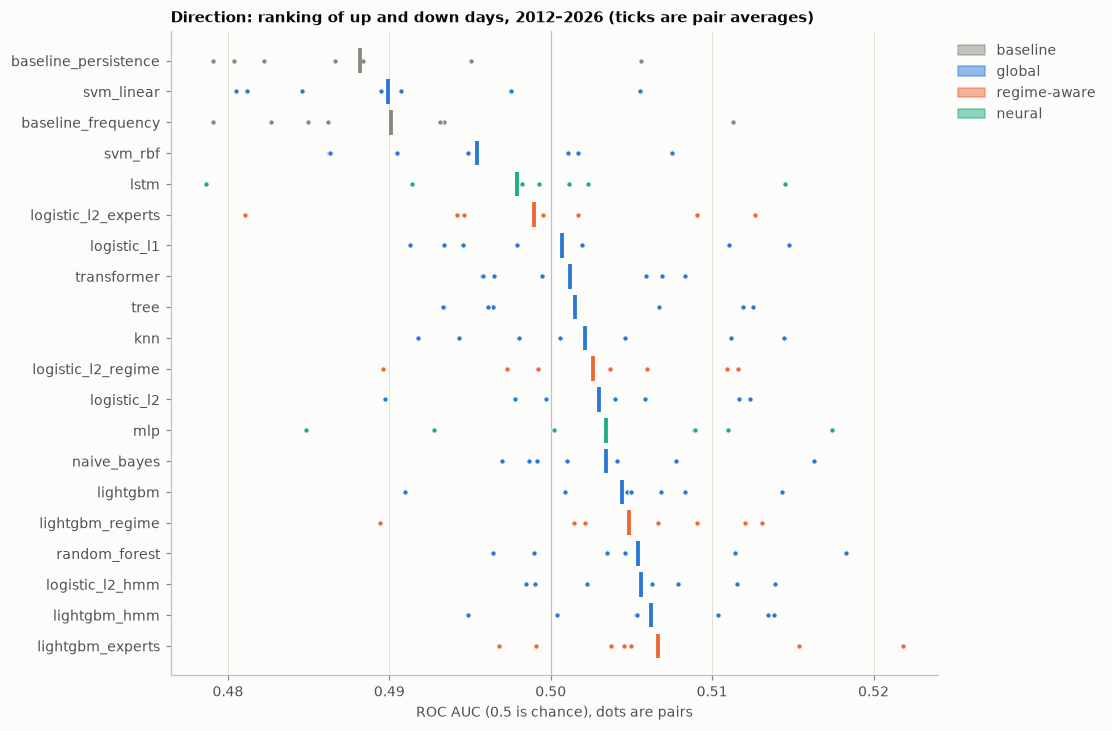

In [6]:
model_chart(direction, "roc_auc", 0.5, "ROC AUC (0.5 is chance), dots are pairs",
            "Direction: ranking of up and down days, 2012–2026 (ticks are pair averages)",
            "ml_direction_auc", lower_is_better=False, bars=False)

In [7]:
# Brier score against the frequency baseline: negative statistics mean the model is better
direction[direction.pair != "average"].pivot(index="pair", columns="model", values="dm_vs_baseline_frequency").loc[pairs].round(2)

model,baseline_frequency,baseline_persistence,knn,lightgbm,lightgbm_experts,lightgbm_hmm,lightgbm_regime,logistic_l1,logistic_l2,logistic_l2_experts,logistic_l2_hmm,logistic_l2_regime,lstm,mlp,naive_bayes,random_forest,svm_linear,svm_rbf,transformer,tree
pair,,,,,,,,,,,,,,,,,,,,
EURUSD,NaN,31.49,2.93,4.20,4.88,4.01,4.78,0.20,0.61,1.49,0.52,0.64,1.27,0.49,4.59,2.21,2.92,0.32,2.70,3.72
GBPUSD,NaN,30.24,1.31,2.48,2.25,2.71,2.64,2.36,1.92,1.70,1.17,2.02,2.21,1.48,5.56,1.01,0.68,1.91,3.69,2.96
USDJPY,NaN,32.40,2.01,2.59,3.73,2.68,2.65,1.34,1.27,0.50,0.52,1.33,0.42,0.37,5.94,-0.17,0.88,2.24,3.01,3.02
USDCHF,NaN,32.28,2.48,3.00,3.57,2.93,2.94,-0.73,-0.35,0.39,-0.28,-0.22,1.12,-0.64,7.50,1.00,2.67,1.58,1.78,2.11
AUDUSD,NaN,33.43,1.79,2.47,4.16,1.73,2.19,-0.04,1.57,1.49,1.05,1.50,0.03,0.32,2.96,0.78,2.78,1.96,1.69,3.88
USDCAD,NaN,33.28,2.47,3.01,4.60,2.80,2.51,0.31,0.87,1.57,0.95,0.93,0.78,0.99,3.89,0.78,2.82,2.12,2.96,3.26
NZDUSD,NaN,33.05,3.31,2.67,3.76,2.61,2.63,-0.17,1.81,3.65,1.17,1.86,1.60,0.31,4.03,1.03,1.40,0.81,3.02,3.64


## Returns

`r2_oos` compares squared errors with always forecasting zero; negative means worse than zero.

In [8]:
ret[ret.pair == "average"].set_index("model")[["rmse", "r2_oos", "sign_hit_rate", "pairs_significantly_better"]].sort_values("r2_oos", ascending=False)

,rmse,r2_oos,sign_hit_rate,pairs_significantly_better
model,,,,
baseline_zero,0.0055,0.0000,NaN,0.0
baseline_mean,0.0055,-0.0005,0.4966,0.0
ridge_regime,0.0056,-0.0021,0.4967,0.0
ridge_hmm,0.0056,-0.0023,0.4966,0.0
ridge_experts,0.0056,-0.0024,0.4936,0.0
ridge,0.0056,-0.0025,0.4961,0.0
baseline_arima,0.0056,-0.0027,0.5028,0.0
mlp,0.0056,-0.0040,0.4985,0.0
lstm,0.0056,-0.0063,0.4980,0.0


## Regime-aware against global models

Diebold–Mariano tests of each regime-aware variant against the same model without regime information.

In [9]:
regime_vs_global[regime_vs_global.pair == "average"].drop(columns=["pair", "dm_vs_global", "dm_p_vs_global"])

,task,model,global_model,pairs_significantly_better,pairs_significantly_worse
126,direction,lightgbm_experts,lightgbm,0.0,5.0
127,direction,lightgbm_hmm,lightgbm,0.0,0.0
128,direction,lightgbm_regime,lightgbm,0.0,0.0
129,direction,logistic_l2_experts,logistic_l2,0.0,1.0
130,direction,logistic_l2_hmm,logistic_l2,3.0,0.0
131,direction,logistic_l2_regime,logistic_l2,0.0,0.0
132,returns,lightgbm_experts,lightgbm,0.0,3.0
133,returns,lightgbm_hmm,lightgbm,0.0,0.0
134,returns,lightgbm_regime,lightgbm,0.0,0.0
135,returns,ridge_experts,ridge,0.0,1.0


In [10]:
# Volatility loss by walk-forward regime: does regime information help where it should?
vol_preds = predictions[predictions.task == "volatility"]
regime = state["regime_gmm"].reindex(vol_preds["date"]).to_numpy()
by_regime = (vol_preds.assign(regime=regime, loss=qlike_losses(vol_preds["actual"], vol_preds["forecast"]))
             .dropna(subset=["regime"]))
show = ["baseline_har", "ridge", "ridge_regime", "ridge_experts", "lightgbm", "lightgbm_regime", "lightgbm_experts"]
table = by_regime[by_regime.model.isin(show)].pivot_table(index="model", columns="regime", values="loss").loc[show]
table.columns = ["calm", "turbulent"]
gain = 100 * (1 - table / table.loc["baseline_har"])
table.assign(**{f"{c}_gain_vs_har_pct": gain[c] for c in table.columns})

,calm,turbulent,calm_gain_vs_har_pct,turbulent_gain_vs_har_pct
model,,,,
baseline_har,0.1427,0.1990,0.0000,0.0000
ridge,0.1409,0.2004,1.2771,-0.7447
ridge_regime,0.1413,0.1995,1.0162,-0.2654
ridge_experts,0.1433,0.2060,-0.3745,-3.5183
lightgbm,0.1351,0.1837,5.3834,7.6648
lightgbm_regime,0.1357,0.1897,4.9430,4.6689
lightgbm_experts,0.1392,0.2011,2.5017,-1.0928


PosixPath('./reports/figures/ml_volatility_by_regime.png')

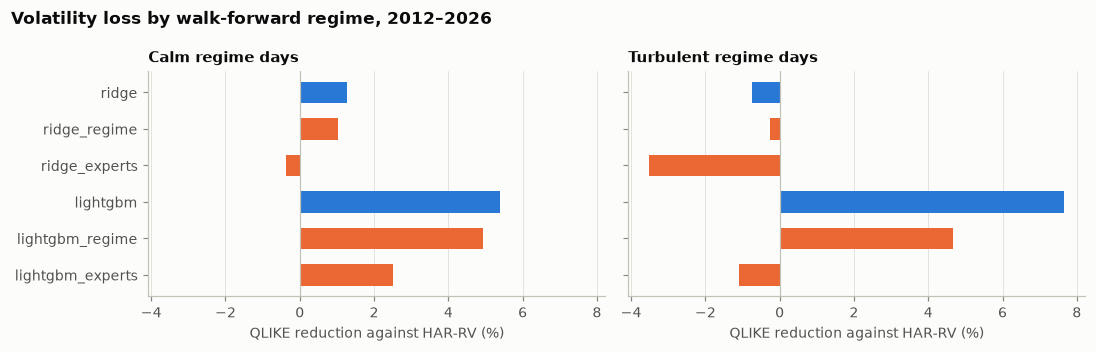

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), sharex=True)
models = gain.drop(index="baseline_har")
for ax, column in zip(axes, table.columns):
    values = models[column]
    colors = [GROUP_COLORS[group_of(m)] for m in values.index]
    ax.barh(values.index, values, color=colors, height=0.6)
    ax.axvline(0, color=viz.BASELINE, lw=0.8)
    ax.set_title(f"{column.capitalize()} regime days")
    ax.invert_yaxis()
    ax.grid(axis="x")
    ax.grid(axis="y", visible=False)
    ax.set_xlabel("QLIKE reduction against HAR-RV (%)")
axes[1].tick_params(labelleft=False)
fig.suptitle("Volatility loss by walk-forward regime, 2012–2026", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
viz.save(fig, "ml_volatility_by_regime")

## Naive Bayes against logistic regression (RQ5)

Both models are trained on only the most recent *n* days of each training window and forecast the same test months; size 0 is the full expanding window. Hyperparameters are fixed. Two targets: next day direction (almost no signal) and a high volatility day (next day realized variance above its median over the last 63 days, a strong signal).

In [12]:
curves.set_index(["target", "size", "model"])

train_days   days  accuracy  log_loss  \
target          size model                                                
direction       21   logistic        21.0000  26833    0.4967    2.4175   
                     naive_bayes     21.0000  26833    0.4949    5.8345   
                63   logistic        63.0000  26833    0.5029    1.7901   
                     naive_bayes     63.0000  26833    0.4920    3.8687   
                126  logistic       126.0000  26833    0.5036    1.3040   
                     naive_bayes    126.0000  26833    0.5016    2.6902   
                252  logistic       252.0000  26833    0.5016    0.9805   
                     naive_bayes    252.0000  26833    0.4974    2.3745   
                504  logistic       504.0000  26833    0.5016    0.8130   
                     naive_bayes    504.0000  26833    0.5004    2.0677   
                1008 logistic      1008.0000  26833    0.5014    0.7348   
                     naive_bayes   1008.0000  26833    0.5013    1.4306   
                0    logistic      3449.8482  26833    0.4996    0.7024   
                     naive_bayes   3449.8482  26833    0.5025    0.9212   
high_volatility 21   logistic        21.0000  26044    0.5308    1.9851   
                     naive_bayes     21.0000  26044    0.5477    5.6167   
                63   logistic        63.0000  26833    0.5591    1.4930   
                     naive_bayes     63.0000  26833    0.6072    3.7057   
                126  logistic       126.0000  26833    0.5716    1.1364   
                     naive_bayes    126.0000  26833    0.6254    3.0585   
                252  logistic       252.0000  26833    0.6078    0.8551   
                     naive_bayes    252.0000  26833    0.6179    2.9467   
                504  logistic       504.0000  26833    0.6353    0.7071   
                     naive_bayes    504.0000  26833    0.6136    2.8601   
                1008 logistic      1008.0000  26833    0.6583    0.6325   
                     naive_bayes   1008.0000  26833    0.6215    2.5511   
                0    logistic      3387.8482  26833    0.6862    0.5916   
                     naive_bayes   3387.8482  26833    0.6283    2.1511   

                                   brier  roc_auc     ece  pairs_nb_better  \
target          size model                                                   
direction       21   logistic     0.4305   0.4997  0.4039                0   
                     naive_bayes  0.4913   0.4952  0.4860                0   
                63   logistic     0.4032   0.5043  0.3638                0   
                     naive_bayes  0.4690   0.4922  0.4548                0   
                126  logistic     0.3667   0.5062  0.3070                0   
                     naive_bayes  0.4324   0.5001  0.4035                0   
                252  logistic     0.3273   0.5019  0.2384                0   
                     naive_bayes  0.4271   0.4961  0.3950                0   
                504  logistic     0.2907   0.5016  0.1650                0   
                     naive_bayes  0.4136   0.5013  0.3754                0   
                1008 logistic     0.2673   0.5016  0.1056                0   
                     naive_bayes  0.3600   0.5025  0.2889                0   
                0    logistic     0.2544   0.4984  0.0522                0   
                     naive_bayes  0.2927   0.5030  0.1656                0   
high_volatility 21   logistic     0.3924   0.5362  0.3564                0   
                     naive_bayes  0.4447   0.5598  0.4084                0   
                63   logistic     0.3533   0.5739  0.3058                0   
                     naive_bayes  0.3710   0.6412  0.3608                0   
                126  logistic     0.3194   0.5937  0.2558                0   
                     naive_bayes  0.3468   0.6631  0.3319                0   
                252  logistic     0.2723   0.6415  0.1779          

PosixPath('./reports/figures/ml_learning_curves.png')

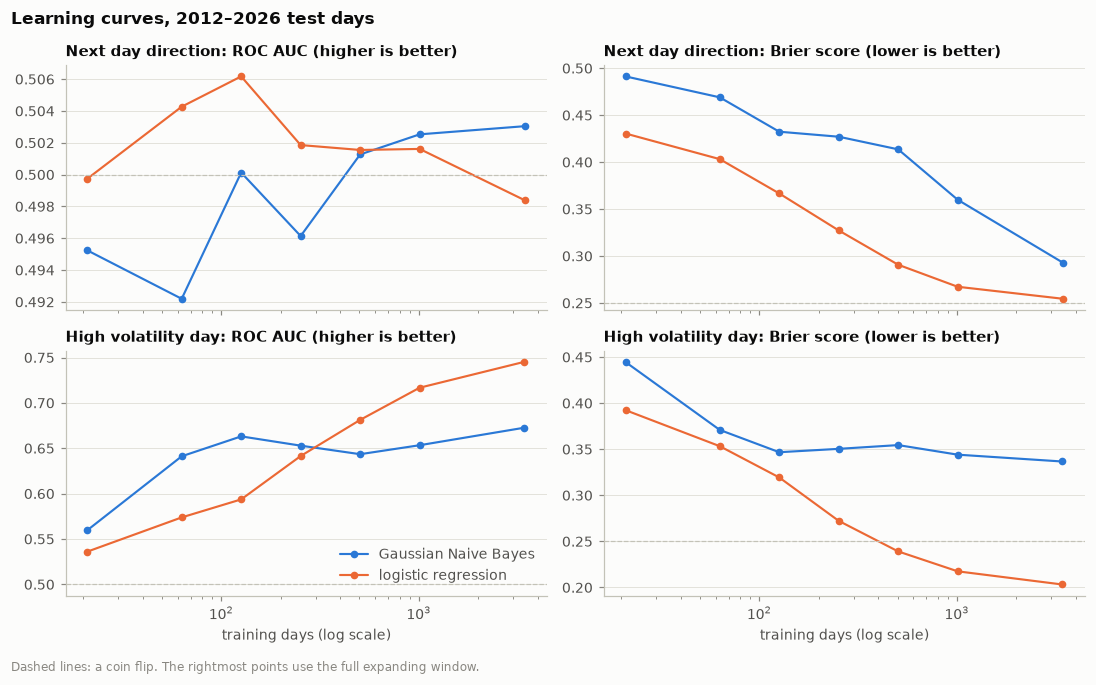

In [13]:
targets = {"direction": "Next day direction", "high_volatility": "High volatility day"}
names = {"naive_bayes": "Gaussian Naive Bayes", "logistic": "logistic regression"}
metrics = {"roc_auc": ("ROC AUC (higher is better)", 0.5), "brier": ("Brier score (lower is better)", 0.25)}
fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharex=True)
for row, (target, target_name) in enumerate(targets.items()):
    for col, (metric, (label, chance)) in enumerate(metrics.items()):
        ax = axes[row, col]
        for i, (model, name) in enumerate(names.items()):
            rows = curves[(curves.target == target) & (curves.model == model)].sort_values("train_days")
            ax.plot(rows.train_days, rows[metric], color=viz.CATEGORICAL[i], marker="o", ms=4, label=name)
        ax.axhline(chance, color=viz.BASELINE, lw=0.8, ls="--")
        ax.set_xscale("log")
        ax.set_title(f"{target_name}: {label}")
axes[1, 0].legend(loc="lower right")
for ax in axes[1]:
    ax.set_xlabel("training days (log scale)")
fig.suptitle("Learning curves, 2012–2026 test days", x=0.01, ha="left", fontweight="bold")
fig.text(0.01, -0.02, "Dashed lines: a coin flip. The rightmost points use the full expanding window.",
         color=viz.INK_MUTED, fontsize=8)
fig.tight_layout()
viz.save(fig, "ml_learning_curves")

## Chosen hyperparameters

In [14]:
(hyper.groupby(["task", "model", "params"]).size().rename("pair_years")
 .reset_index().sort_values(["task", "model", "pair_years"], ascending=[True, True, False])
 .groupby(["task", "model"]).head(2))

,task,model,params,pair_years
1,direction,knn,"{""n_neighbors"": 200}",78
0,direction,knn,"{""n_neighbors"": 100}",24
4,direction,lightgbm,"{""n_estimators"": 150, ""num_leaves"": 7}",102
3,direction,lightgbm,"{""n_estimators"": 150, ""num_leaves"": 15}",3
6,direction,lightgbm_experts,"{""n_estimators"": 150, ""num_leaves"": 7}",101
...,...,...,...,...
91,volatility,ridge_experts,"{""alpha"": 1}",29
95,volatility,ridge_hmm,"{""alpha"": 1}",51
92,volatility,ridge_hmm,"{""alpha"": 1000}",33
99,volatility,ridge_regime,"{""alpha"": 1}",46


## Findings

**Volatility: LightGBM beats HAR-RV; the linear models and the random forest only match it.** LightGBM lowers the average QLIKE loss from 0.157 to 0.147, 6.1% less than HAR-RV. Per pair the gain runs from 3.6% (USD/CHF) to 9.8% (AUD/USD) and is significant on 5 of 7 pairs; GBP/USD and USD/CHF are the exceptions. Its forecasts are also almost unbiased (Mincer–Zarnowitz slope 0.99 against 0.93 for HAR-RV). Ridge, lasso and the random forest improve on HAR-RV by only 0.6% to 1.1% on average, each significantly on 3 pairs. k-nearest neighbours is 15% worse: with 50 features every day is far from every other. LightGBM gains more on turbulent days (7.7%) than on calm ones (5.4%). USD/CHF stays the hardest pair because the January 2015 franc shock dominates its losses.

**Regime information does not help.** Adding the turbulent regime probability as a feature makes no measurable difference: no regime-aware variant is significantly better than its global model on any pair, apart from ridge returns on one pair. One expert per regime is worse. LightGBM experts are significantly worse than global LightGBM on 4 pairs for volatility and 5 for direction, and they lose most on turbulent days, where each expert has only about a quarter of the history. A global LightGBM already conditions on volatility through its features, so splitting the data mainly costs it observations. With two regimes from the market state, the second half of H3 (regime-aware models beat global ones) is not supported. Hidden Markov model regimes, added as an extension (`*_hmm`, notebook 08), do not change this for volatility either.

**Direction is not predictable.** Accuracy stays between 48.3% and 51.5% and ROC AUC between 0.48 and 0.52 for every model and pair. No model's calls beat chance on the Pesaran–Timmermann test on any pair, and none has a lower Brier score than the historical frequency of up days on any pair. LightGBM, Naive Bayes and the decision tree are significantly worse than that frequency on all seven. Tuning tells the same story: for logistic regression it chose the strongest regularisation on offer (C = 0.001) in 100 of 105 pair years, the closest it could get to a constant forecast.

**Returns are not predictable either.** Every model has a negative out-of-sample R² against the zero forecast (ridge −0.25%, LightGBM −2.1%) and none beats zero on any pair. Ridge tuning chose the largest penalty in most years.

**RQ5: Naive Bayes learns faster and logistic regression learns more.** On next day direction neither model learns anything at any window length; the curves only show logistic regression overfitting less. On the high volatility target Naive Bayes ranks days better with up to a year of data (AUC 0.66 against 0.59 at 126 days). Logistic regression overtakes it between one and two years and keeps improving (0.75 against 0.67 on the full window), while Naive Bayes levels off. Naive Bayes's probabilities are poorly calibrated at every size (Brier score 0.34 against 0.20 on the full window) because the features are strongly correlated, which breaks its independence assumption. H5 holds for ranking days, not for calibrated probabilities.

**For Phases 5 and 6.** LightGBM is the volatility model the neural networks have to beat. Any economic value is likely to come from volatility forecasts (volatility targeting and Value at Risk) rather than from direction signals, which are unlikely to survive trading costs.